# Travel Planner — Variation Evaluation

Compares all run artifacts across:
- **Baseline vs Enhanced** (model quality improvement)
- **Temperature sweep** (0.2 / 0.4 / 0.7 — conservative → creative)
- **Named runs** (conservative, creative)

Metrics: ROUGE-L, BLEU, Constraint Score, Delivery Rate, Audit Pass Rate, Plan Length

In [1]:
import sys, json
from pathlib import Path

ROOT = Path('.').resolve()
sys.path.insert(0, str(ROOT / 'src'))

import warnings
warnings.filterwarnings('ignore')

print('Root:', ROOT)

Root: /Users/mac/Desktop/Group 7/phase2_improved


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({
    'figure.facecolor': '#0f1117',
    'axes.facecolor':   '#1a2035',
    'axes.edgecolor':   '#2d3a52',
    'axes.labelcolor':  '#c9d1d9',
    'xtick.color':      '#8ab4d4',
    'ytick.color':      '#8ab4d4',
    'text.color':       '#e0f0ff',
    'grid.color':       '#2d3a52',
    'grid.linestyle':   '--',
    'grid.alpha':       0.4,
    'font.family':      'DejaVu Sans',
})
print('Matplotlib dark theme ready')

Matplotlib dark theme ready


## 1 — Load all artifact files

In [3]:
from travel_planner.config import HF_TOKEN
from travel_planner.data.load_travelplanner import load_split

print('Loading validation split for reference plans…')
ds = load_split(split='validation', token=HF_TOKEN)
print(f'Validation rows: {len(ds)}')
print('Columns:', ds.column_names[:8])

Loading validation split for reference plans…


Validation rows: 180
Columns: ['org', 'dest', 'days', 'visiting_city_number', 'date', 'people_number', 'local_constraint', 'budget']


In [4]:
ARTIFACT_FILES = {
    'baseline':       'artifacts/runs/baseline_runs.jsonl',
    'enhanced':       'artifacts/runs/enhanced_runs.jsonl',
    'temp_0.2':       'artifacts/runs/temp_0.2_runs.jsonl',
    'temp_0.7':       'artifacts/runs/temp_0.7_runs.jsonl',
    'freq_pen_0.3':   'artifacts/runs/freq_penalty_0.3_runs.jsonl',
    'max_tok_384':    'artifacts/runs/max_tokens_384_runs.jsonl',
    'top_p_0.8':      'artifacts/runs/top_p_0.8_runs.jsonl',
}

def load_jsonl(path):
    rows = []
    p = ROOT / path
    if not p.exists():
        print(f'  ⚠️  {path} not found — skipping')
        return rows
    for line in p.read_text().splitlines():
        line = line.strip()
        if line:
            rows.append(json.loads(line))
    return rows

artifacts = {name: load_jsonl(path) for name, path in ARTIFACT_FILES.items()}
for name, rows in artifacts.items():
    print(f'  {name:15s}: {len(rows)} rows')

  baseline       : 5 rows
  enhanced       : 5 rows
  temp_0.2       : 5 rows
  temp_0.7       : 5 rows
  freq_pen_0.3   : 5 rows
  max_tok_384    : 5 rows
  top_p_0.8      : 5 rows


## 2 — Compute metrics for every run

In [5]:
from travel_planner.eval.metrics_improved import (
    evaluate_record_with_reference,
    aggregate_improved,
)

def score_artifact(name, rows):
    """Evaluate all rows in a JSONL artifact against the validation reference."""
    if not rows:
        return None
    records = []
    for rec in rows:
        idx = int(rec.get('row_index', 0))
        if idx >= len(ds):
            continue
        row      = ds[idx]
        plan     = rec.get('plan') or rec.get('output') or ''
        cons     = rec.get('constraints') or {}
        if isinstance(cons, str):
            try:   cons = json.loads(cons)
            except: cons = {}
        reference = row.get('annotated_plan') or row.get('reference_information') or ''
        er = evaluate_record_with_reference(plan, reference, row=row, constraints=cons)
        er['run']         = name
        er['row_index']   = idx
        er['temperature'] = rec.get('temperature')
        er['audit_passed'] = rec.get('audit_passed')
        er['plan_len']    = len(plan)
        records.append(er)
    return records

all_records = {}
for name, rows in artifacts.items():
    recs = score_artifact(name, rows)
    if recs:
        all_records[name] = recs
        print(f'  ✅  {name:15s}: {len(recs)} records scored')
    else:
        print(f'  ⚠️  {name}: no records')

rouge_score not installed. ROUGE metrics will be skipped.


  ✅  baseline       : 5 records scored


  ✅  enhanced       : 5 records scored


  ✅  temp_0.2       : 5 records scored


  ✅  temp_0.7       : 5 records scored


  ✅  freq_pen_0.3   : 5 records scored


  ✅  max_tok_384    : 5 records scored


  ✅  top_p_0.8      : 5 records scored


## 3 — Aggregate summary table

In [6]:
summary_rows = []
for name, recs in all_records.items():
    agg = aggregate_improved(recs)
    temps = [r['temperature'] for r in recs if r.get('temperature') is not None]
    audits = [r['audit_passed'] for r in recs if r.get('audit_passed') is not None]
    summary_rows.append({
        'Run':              name,
        'N':                int(agg['n']),
        'Temperature':      round(temps[0], 2) if temps else '—',
        'Delivery %':       round(agg['delivery_rate'] * 100, 1),
        'Commonsense %':    round(agg['commonsense_rate'] * 100, 1),
        'Hard Constraint %': round(agg['hard_constraint_rate'] * 100, 1),
        'ROUGE-L':          round(agg['avg_rougeL'], 4),
        'BLEU':             round(agg.get('avg_bleu', 0.0), 4),
        'Semantic Sim':     round(agg['avg_semantic_similarity'], 4),
        'Constraint Score': round(agg['avg_constraint_score'], 4),
        'Structure Score':  round(agg['avg_structure_score'], 4),
        'Audit Pass %':     round(sum(audits) / len(audits) * 100, 1) if audits else '—',
        'Avg Plan Len':     round(sum(r['plan_len'] for r in recs) / len(recs)),
    })

df = pd.DataFrame(summary_rows).set_index('Run')

# Style the table
styled = df.style \
    .background_gradient(subset=['ROUGE-L', 'BLEU', 'Semantic Sim'], cmap='Blues') \
    .background_gradient(subset=['Delivery %', 'Constraint Score'], cmap='Greens') \
    .background_gradient(subset=['Avg Plan Len'], cmap='Oranges') \
    .format(precision=4)

print('Summary table:')
display(styled)

Summary table:


,N,Temperature,Delivery %,Commonsense %,Hard Constraint %,ROUGE-L,BLEU,Semantic Sim,Constraint Score,Structure Score,Audit Pass %,Avg Plan Len
Run,,,,,,,,,,,,
baseline,5,0.4000,100.0000,100.0000,0.0000,0.0000,0.0069,0.5207,0.6000,1.0000,100.0000,2367
enhanced,5,0.4000,40.0000,0.0000,20.0000,0.0000,0.0065,0.7961,0.3600,0.1200,0.0000,2641
temp_0.2,5,0.2000,100.0000,100.0000,0.0000,0.0000,0.0009,0.4832,0.6000,1.0000,60.0000,2043
temp_0.7,5,0.7000,100.0000,100.0000,0.0000,0.0000,0.0064,0.5490,0.6000,1.0000,100.0000,2301
freq_pen_0.3,5,0.4000,100.0000,100.0000,100.0000,0.0000,0.0000,0.1058,0.5000,0.6000,100.0000,259
max_tok_384,5,0.4000,100.0000,100.0000,100.0000,0.0000,0.0000,0.1058,0.5000,0.6000,100.0000,259
top_p_0.8,5,0.4000,100.0000,100.0000,60.0000,0.0000,0.0000,0.2270,0.5200,0.6800,100.0000,584


## 4 — Bar chart: ROUGE-L · BLEU · Semantic Similarity

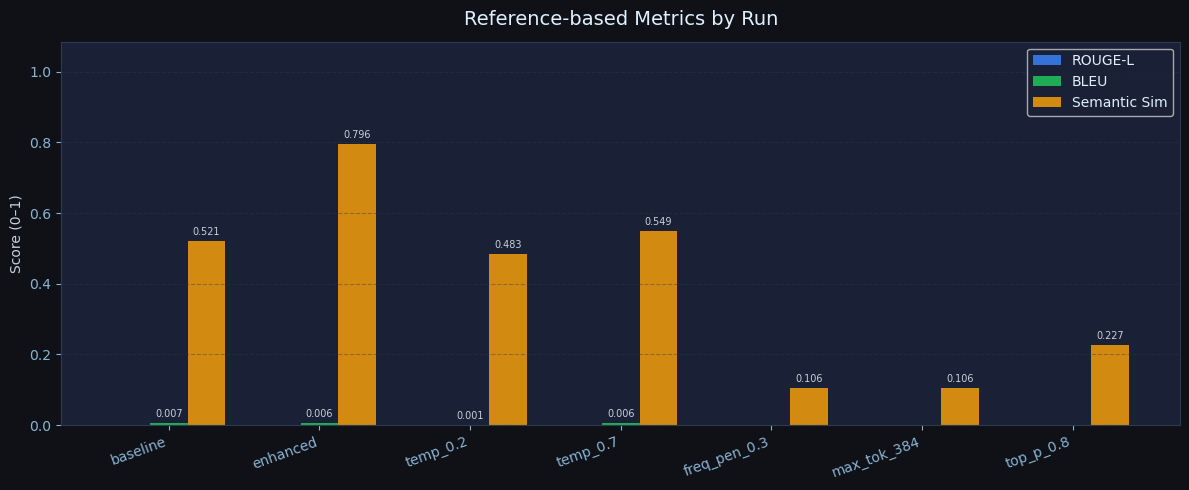

Saved → artifacts/eval_reference_metrics.png


In [7]:
runs   = df.index.tolist()
x      = np.arange(len(runs))
width  = 0.25
colors = ['#3b82f6', '#22c55e', '#f59e0b']

fig, ax = plt.subplots(figsize=(12, 5))
b1 = ax.bar(x - width, df['ROUGE-L'],       width, label='ROUGE-L',       color=colors[0], alpha=0.85)
b2 = ax.bar(x,          df['BLEU'],          width, label='BLEU',          color=colors[1], alpha=0.85)
b3 = ax.bar(x + width,  df['Semantic Sim'],  width, label='Semantic Sim',  color=colors[2], alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(runs, rotation=20, ha='right')
ax.set_ylabel('Score (0–1)')
ax.set_title('Reference-based Metrics by Run', fontsize=14, pad=12)
ax.legend()
ax.grid(axis='y')
ax.set_ylim(0, max(df[['ROUGE-L','BLEU','Semantic Sim']].max()) * 1.3 + 0.05)

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.annotate(f'{h:.3f}',
                xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=7, color='#c9d1d9')

fig.tight_layout()
plt.savefig('artifacts/eval/eval_reference_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → artifacts/eval_reference_metrics.png')

## 5 — Temperature sweep: ROUGE-L vs Temperature

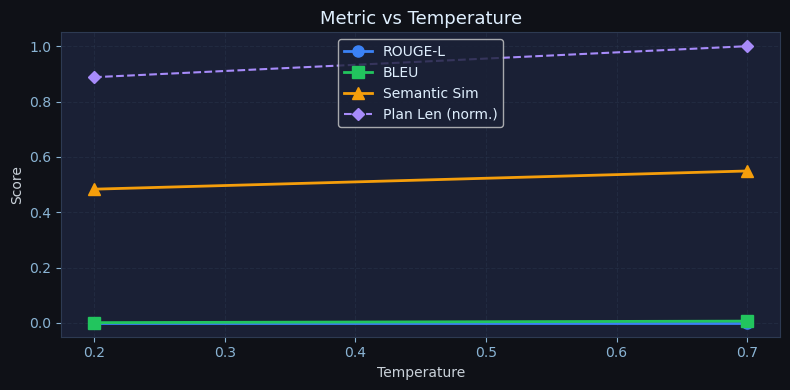

Saved → artifacts/eval_temperature_sweep.png


In [8]:
temp_runs = [r for r in summary_rows if r['Run'].startswith('temp_')]
temp_runs_sorted = sorted(temp_runs, key=lambda r: float(r['Temperature']) if r['Temperature'] != '—' else 0)

if temp_runs_sorted:
    temps   = [r['Temperature'] for r in temp_runs_sorted]
    rouge_l = [r['ROUGE-L']     for r in temp_runs_sorted]
    bleu    = [r['BLEU']        for r in temp_runs_sorted]
    sem     = [r['Semantic Sim'] for r in temp_runs_sorted]
    pllen   = [r['Avg Plan Len'] / max(r['Avg Plan Len'] for r in temp_runs_sorted)
               for r in temp_runs_sorted]  # normalised

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(temps, rouge_l, 'o-', color='#3b82f6', lw=2, ms=8, label='ROUGE-L')
    ax.plot(temps, bleu,    's-', color='#22c55e', lw=2, ms=8, label='BLEU')
    ax.plot(temps, sem,     '^-', color='#f59e0b', lw=2, ms=8, label='Semantic Sim')
    ax.plot(temps, pllen,   'D--', color='#a78bfa', lw=1.5, ms=6, label='Plan Len (norm.)')

    ax.set_xlabel('Temperature')
    ax.set_ylabel('Score')
    ax.set_title('Metric vs Temperature', fontsize=13)
    ax.legend()
    ax.grid()
    fig.tight_layout()
    plt.savefig('artifacts/eval/eval_temperature_sweep.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Saved → artifacts/eval_temperature_sweep.png')
else:
    print('No temperature-sweep runs found.')

## 6 — Baseline vs Enhanced comparison

Baseline vs Enhanced:


,Baseline,Enhanced,Δ
ROUGE-L,0.0000,0.0000,0.0000
BLEU,0.0069,0.0065,-0.0004
Semantic Sim,0.5207,0.7961,0.2754
Constraint Score,0.6000,0.3600,-0.2400
Structure Score,1.0000,0.1200,-0.8800


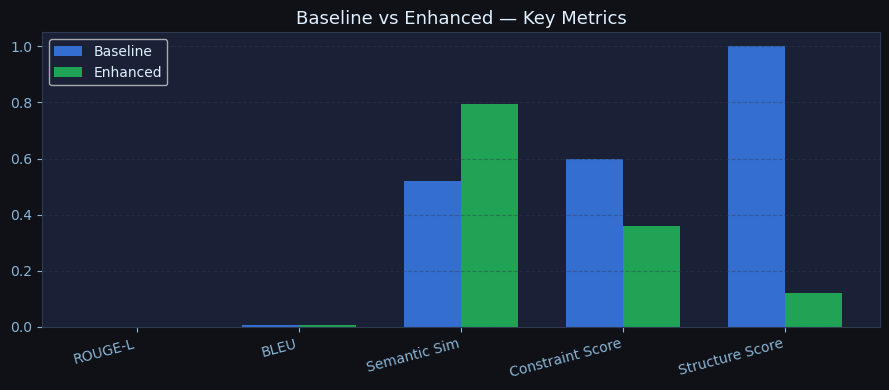

Saved → artifacts/eval_baseline_vs_enhanced.png


In [9]:
metrics_to_compare = ['ROUGE-L', 'BLEU', 'Semantic Sim', 'Constraint Score', 'Structure Score']

if 'baseline' in df.index and 'enhanced' in df.index:
    base = df.loc['baseline', metrics_to_compare]
    enh  = df.loc['enhanced',  metrics_to_compare]
    diff = (enh - base).rename('Δ (enhanced − baseline)')

    cmp_df = pd.DataFrame({'Baseline': base, 'Enhanced': enh, 'Δ': diff})
    print('Baseline vs Enhanced:')
    display(cmp_df.style
        .background_gradient(subset=['Δ'], cmap='RdYlGn')
        .format(precision=4))

    fig, ax = plt.subplots(figsize=(9, 4))
    x   = np.arange(len(metrics_to_compare))
    w   = 0.35
    ax.bar(x - w/2, base.values, w, label='Baseline', color='#3b82f6', alpha=0.8)
    ax.bar(x + w/2, enh.values,  w, label='Enhanced', color='#22c55e', alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_to_compare, rotation=15, ha='right')
    ax.set_title('Baseline vs Enhanced — Key Metrics', fontsize=13)
    ax.legend()
    ax.grid(axis='y')
    fig.tight_layout()
    plt.savefig('artifacts/eval/eval_baseline_vs_enhanced.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Saved → artifacts/eval_baseline_vs_enhanced.png')
else:
    print('baseline or enhanced artifact not found.')

## 7 — Audit pass rate across all runs

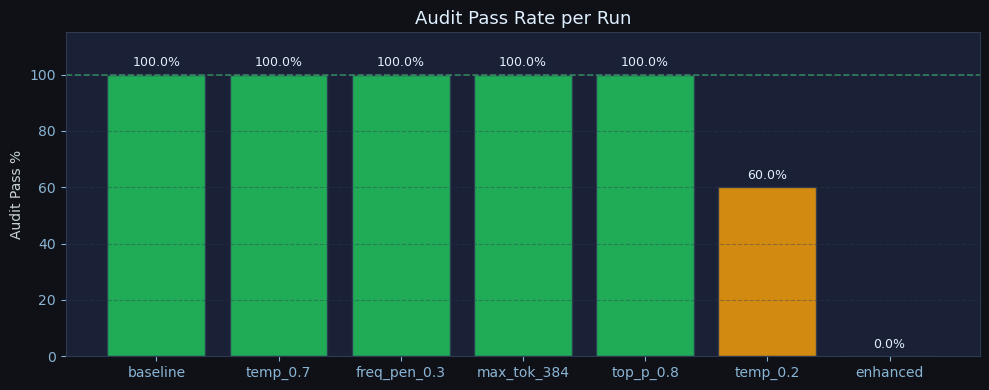

In [10]:
audit_data = [(r['Run'], r['Audit Pass %']) for r in summary_rows if r['Audit Pass %'] != '—']

if audit_data:
    a_runs, a_vals = zip(*sorted(audit_data, key=lambda x: x[1], reverse=True))
    colors_bar = ['#22c55e' if v == 100 else '#f59e0b' if v >= 50 else '#ef4444'
                  for v in a_vals]

    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.bar(a_runs, a_vals, color=colors_bar, alpha=0.85, edgecolor='#2d3a52')
    ax.set_ylim(0, 115)
    ax.set_ylabel('Audit Pass %')
    ax.set_title('Audit Pass Rate per Run', fontsize=13)
    ax.axhline(100, color='#4ade80', lw=1.2, ls='--', alpha=0.5)
    ax.grid(axis='y')
    for bar, val in zip(bars, a_vals):
        ax.text(bar.get_x() + bar.get_width()/2, val + 2, f'{val}%',
                ha='center', va='bottom', fontsize=9, color='#e0f0ff')
    fig.tight_layout()
    plt.savefig('artifacts/eval/eval_audit_pass.png', dpi=150, bbox_inches='tight')
    plt.show()

## 8 — Average plan length by run

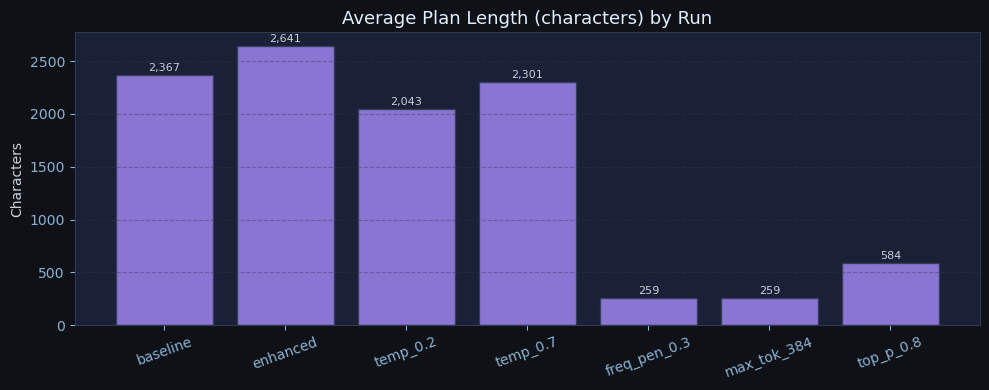

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(df.index, df['Avg Plan Len'], color='#a78bfa', alpha=0.8, edgecolor='#2d3a52')
ax.set_ylabel('Characters')
ax.set_title('Average Plan Length (characters) by Run', fontsize=13)
ax.tick_params(axis='x', rotation=20)
ax.grid(axis='y')
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 20, f'{int(h):,}',
            ha='center', va='bottom', fontsize=8, color='#c9d1d9')
fig.tight_layout()
plt.savefig('artifacts/eval/eval_plan_length.png', dpi=150, bbox_inches='tight')
plt.show()

## 9 — Per-row detail: inspect any run

In [12]:
# Change these to inspect any combination
RUN_A = 'baseline'
RUN_B = 'enhanced'

def records_to_df(name):
    recs = all_records.get(name, [])
    return pd.DataFrame(recs)[['row_index','temperature','audit_passed',
                                 'plan_len','ROUGE-L' if 'ROUGE-L' in
                                 (recs[0] if recs else {}) else 'rouge_l_fmeasure',
                                 'bleu_score','semantic_similarity','constraint_score']] \
                         .rename(columns={'rouge_l_fmeasure':'ROUGE-L','bleu_score':'BLEU',
                                          'semantic_similarity':'Semantic Sim',
                                          'constraint_score':'Constraint'})

try:
    col1, col2 = RUN_A, RUN_B
    df_a = pd.DataFrame(all_records[col1])[['row_index','rouge_l_fmeasure','bleu_score',
                                             'semantic_similarity','constraint_score','plan_len']]
    df_b = pd.DataFrame(all_records[col2])[['row_index','rouge_l_fmeasure','bleu_score',
                                             'semantic_similarity','constraint_score','plan_len']]
    df_a = df_a.rename(columns={c: f'{col1}/{c}' for c in df_a.columns if c != 'row_index'})
    df_b = df_b.rename(columns={c: f'{col2}/{c}' for c in df_b.columns if c != 'row_index'})
    merged = df_a.merge(df_b, on='row_index', how='outer')
    print(f'Per-row comparison: {col1} vs {col2}')
    display(merged.style.format(precision=4))
except Exception as e:
    print('Could not build comparison:', e)

Per-row comparison: baseline vs enhanced


,row_index,baseline/rouge_l_fmeasure,baseline/bleu_score,baseline/semantic_similarity,baseline/constraint_score,baseline/plan_len,enhanced/rouge_l_fmeasure,enhanced/bleu_score,enhanced/semantic_similarity,enhanced/constraint_score,enhanced/plan_len
0,0,0.0000,0.0199,0.5894,0.6000,2789,0.0000,0.0032,0.8514,0.2500,2104
1,1,0.0000,0.0011,0.5218,0.6000,1627,0.0000,0.0164,0.9445,0.2500,2886
2,2,0.0000,0.0040,0.4787,0.6000,2502,0.0000,0.0088,0.9371,0.2500,2902
3,3,0.0000,0.0038,0.5467,0.6000,2184,0.0000,0.0039,0.6226,0.8000,3035
4,4,0.0000,0.0056,0.4669,0.6000,2732,0.0000,0.0000,0.6247,0.2500,2279


## 10 — Export full results CSV

In [13]:
all_flat = []
for name, recs in all_records.items():
    for r in recs:
        all_flat.append(r)

df_all = pd.DataFrame(all_flat)
out_csv = ROOT / 'artifacts' / 'evaluation_all_runs.csv'
df_all.to_csv(out_csv, index=False)
print(f'Exported {len(df_all)} rows → {out_csv}')
display(df_all.groupby('run')[[
    'rouge_l_fmeasure','bleu_score','semantic_similarity',
    'constraint_score','structure_score','plan_len'
]].mean().round(4).style.background_gradient(cmap='Blues'))

Exported 35 rows → /Users/mac/Desktop/Group 7/phase2_improved/artifacts/evaluation_all_runs.csv


,rouge_l_fmeasure,bleu_score,semantic_similarity,constraint_score,structure_score,plan_len
run,,,,,,
baseline,0.000000,0.006900,0.520700,0.600000,1.000000,2366.800000
enhanced,0.000000,0.006500,0.796100,0.360000,0.120000,2641.200000
freq_pen_0.3,0.000000,0.000000,0.105800,0.500000,0.600000,259.000000
max_tok_384,0.000000,0.000000,0.105800,0.500000,0.600000,259.000000
temp_0.2,0.000000,0.000900,0.483200,0.600000,1.000000,2043.000000
temp_0.7,0.000000,0.006400,0.549000,0.600000,1.000000,2300.800000
top_p_0.8,0.000000,0.000000,0.227000,0.520000,0.680000,583.600000
